## Synthetic Well Log Generation for Sabah Deepwater and Abu Dhabi Carbonates

#### Keith R. Holdaway FGS

### This code creates two synthetic datasets:

### Sabah Deepwater Clastics Dataset:
#### Represents a deepwater turbidite sequence with alternating sand and shale

#### Includes:

#### Hydrocarbon-bearing sandstone reservoir (high resistivity, low GR)

#### Water-bearing sandstone (low resistivity, low GR)

#### Thin-bedded sequences

#### Shale intervals (high GR, low resistivity)

### Abu Dhabi Carbonates Dataset:
#### Represents a carbonate platform environment

#### Includes:

#### Porous limestone reservoir (good porosity, high resistivity)

#### Dolomite reservoir (identified by low PEF values)

#### Tight non-porous limestone (very high resistivity, low porosity)

#### Unconventional carbonate mudstone (high GR, moderate resistivity)

### The code generates realistic-looking logs with appropriate:

#### Absolute values for each log type

#### Relationships between different logs

#### Geological trends with depth

#### Random noise to simulate real measurement variability

### Separate Tracks for NPHI and RHOB:

#### Added a dedicated track for RHOB with appropriate scaling (1.95-2.95 g/cm³)

#### Kept NPHI in its own track with proper scaling (0.45 to -0.15 v/v)

### Improved Visualization:

#### Added fill between the curves and the right side of the track to enhance visibility

#### Used standard industry ranges for each measurement

#### Added a sixth track for PEF in the Abu Dhabi dataset

### Standard Industry Scales:

#### NPHI: 0.45 to -0.15 (limestone matrix)

#### RHOB: 1.95 to 2.95 g/cm³

#### GR: 0 to 150 API

#### Resistivity: 0.2 to 2000 ohm.m (log scale)

#### DT: 40 to 140 μs/ft

Generating Sabah Deepwater synthetic logs...
Sabah dataset sample:
    DEPTH          GR        RT      NPHI      RHOB         DT
0  2300.0  153.204860  2.912792  0.589733  2.568329  94.589580
1  2300.5  151.749891  2.868312  0.548866  2.570626  96.827119
2  2301.0  158.487430  2.762239  0.543148  2.563069  95.726909
3  2301.5  154.846904  3.072856  0.613446  2.575622  93.972575
4  2302.0  159.536023  3.091979  0.562209  2.568455  95.341753

Generating Abu Dhabi synthetic logs...
Abu Dhabi dataset sample:
    DEPTH         GR          RT      NPHI      RHOB         DT       PEF
0  2800.0  26.456864   87.020350  0.053843  2.704401  47.176495  4.985908
1  2800.5  28.264206   95.115834  0.030636  2.711791  49.382678  4.769175
2  2801.0  28.129779   96.757274  0.052015  2.699322  49.816921  4.993763
3  2801.5  26.786404  103.872894  0.049266  2.677312  50.238446  5.139739
4  2802.0  27.015335   95.527679  0.047290  2.722944  49.745030  4.748310


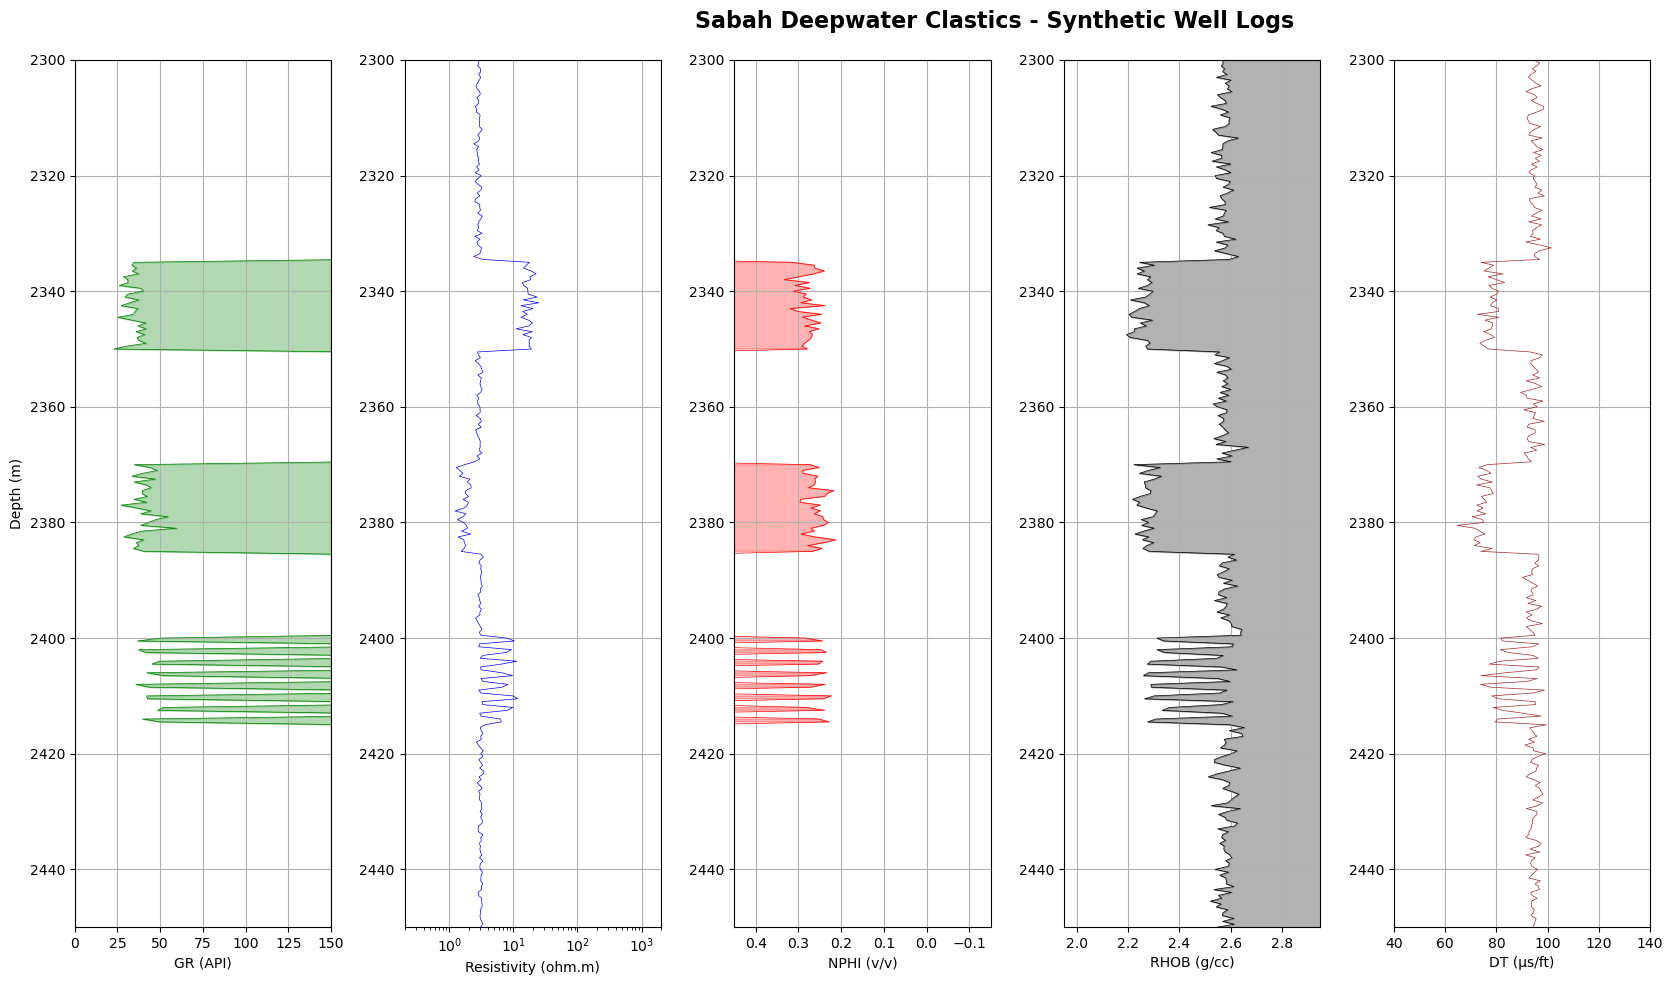

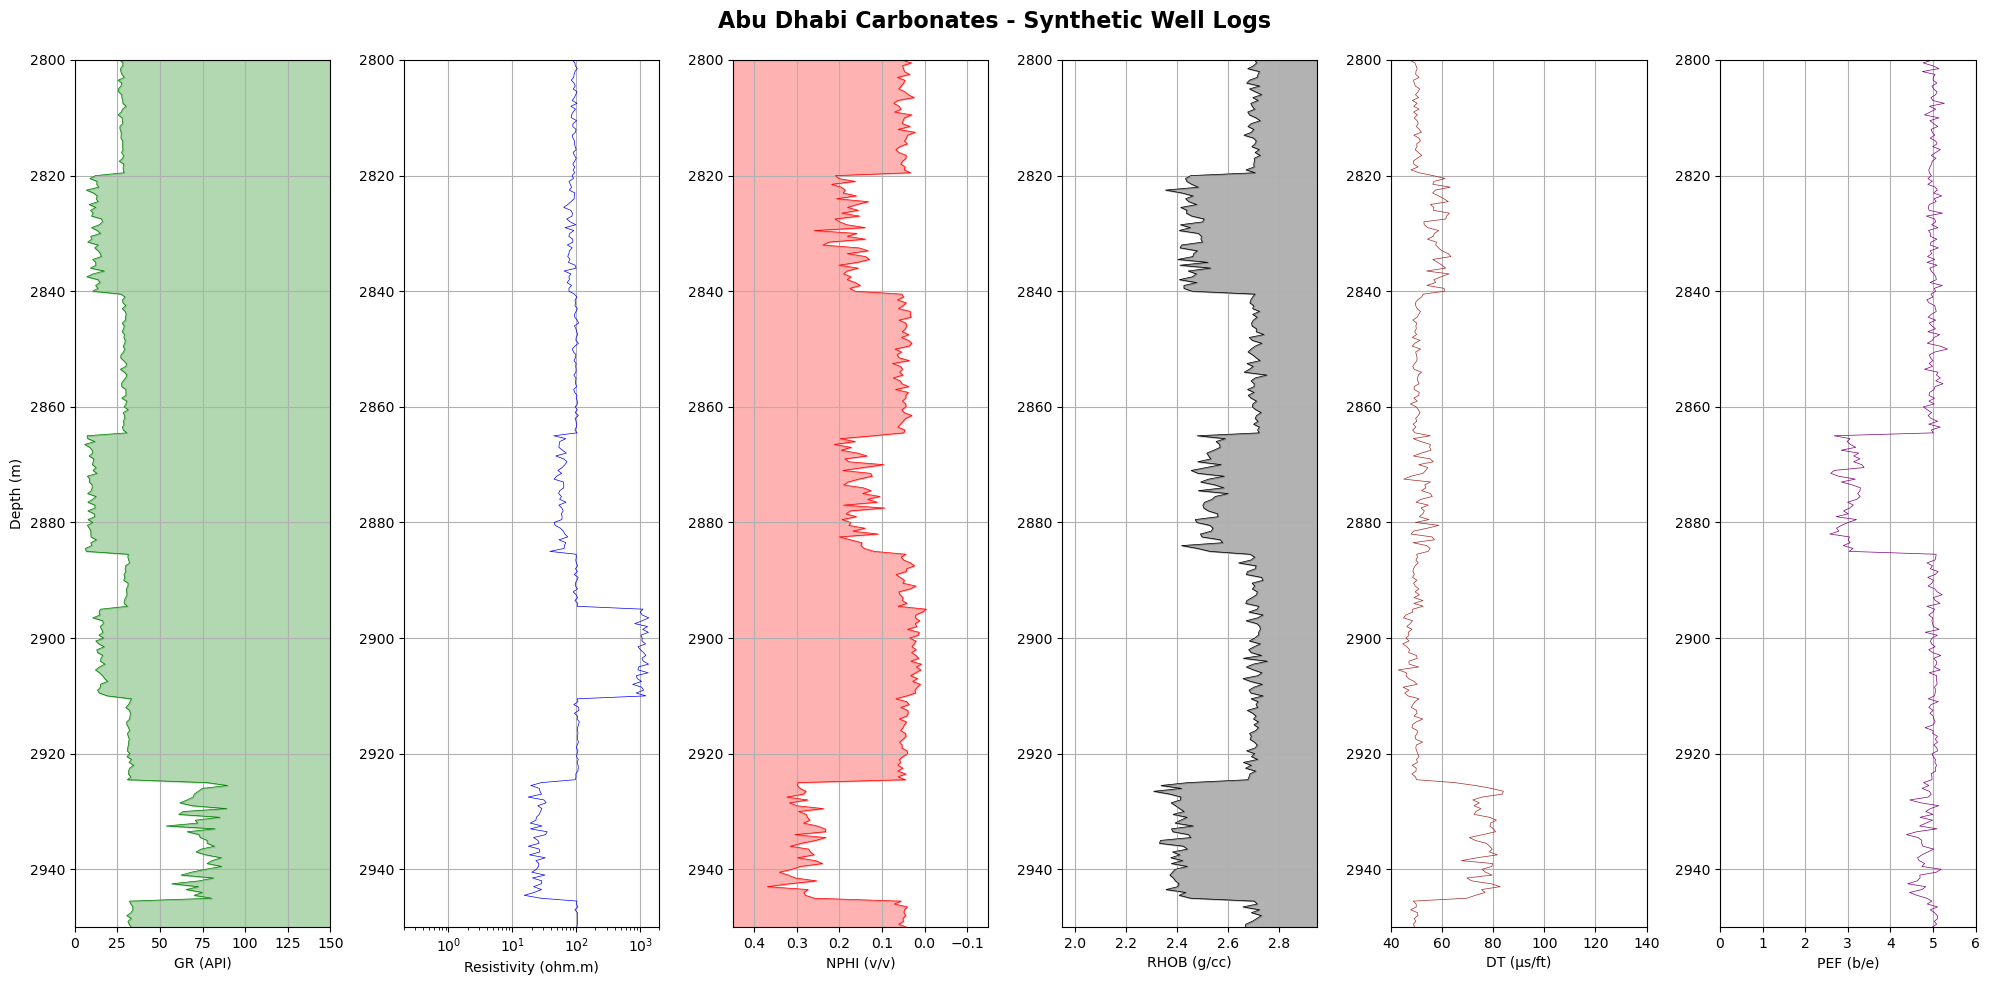


Datasets saved as 'sabah_deepwater_logs.csv' and 'abu_dhabi_logs.csv'


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def generate_sabah_deepwater_logs():
    """
    Generate synthetic well logs for Sabah deepwater clastic environment
    """
    # Create depth array from 2300 to 2450 meters with 0.5m sampling
    depth = np.arange(2300, 2450.5, 0.5)
    n_samples = len(depth)
    
    # Initialize log arrays
    gr = np.ones(n_samples) * 80  # Baseline shale GR
    rt = np.ones(n_samples) * 1.5  # Baseline resistivity
    nphi = np.ones(n_samples) * 0.38  # Baseline neutron porosity
    rhob = np.ones(n_samples) * 2.35  # Baseline density
    dt = np.ones(n_samples) * 95  # Baseline sonic
    
    # Add geological trends
    gr_trend = np.linspace(75, 85, n_samples)  # Gradual increase in GR with depth
    rt_trend = np.linspace(1.3, 1.7, n_samples)  # Slight increase in resistivity
    nphi_trend = np.linspace(0.40, 0.35, n_samples)  # Compaction trend
    rhob_trend = np.linspace(2.30, 2.40, n_samples)  # Compaction trend
    
    # Add the trends
    gr += gr_trend + np.random.normal(0, 3, n_samples)  # Add noise
    rt += rt_trend + np.random.normal(0, 0.2, n_samples)
    nphi += nphi_trend/2 + np.random.normal(0, 0.02, n_samples)
    rhob += rhob_trend/10 + np.random.normal(0, 0.03, n_samples)
    dt += np.random.normal(0, 2, n_samples)
    
    # Create reservoir zones
    # First sand package: 2335-2350m (oil-bearing)
    sand1_mask = (depth >= 2335) & (depth <= 2350)
    gr[sand1_mask] = 35 + np.random.normal(0, 5, np.sum(sand1_mask))
    rt[sand1_mask] = 18 + np.random.normal(0, 3, np.sum(sand1_mask))
    nphi[sand1_mask] = 0.28 + np.random.normal(0, 0.02, np.sum(sand1_mask))
    rhob[sand1_mask] = 2.25 + np.random.normal(0, 0.03, np.sum(sand1_mask))
    dt[sand1_mask] = 78 + np.random.normal(0, 3, np.sum(sand1_mask))
    
    # Second sand package: 2370-2385m (water-bearing)
    sand2_mask = (depth >= 2370) & (depth <= 2385)
    gr[sand2_mask] = 40 + np.random.normal(0, 5, np.sum(sand2_mask))
    rt[sand2_mask] = 1.8 + np.random.normal(0, 0.3, np.sum(sand2_mask))
    nphi[sand2_mask] = 0.26 + np.random.normal(0, 0.02, np.sum(sand2_mask))
    rhob[sand2_mask] = 2.27 + np.random.normal(0, 0.03, np.sum(sand2_mask))
    dt[sand2_mask] = 75 + np.random.normal(0, 3, np.sum(sand2_mask))
    
    # Thin bed sequence: 2400-2415m
    thin_bed_mask = (depth >= 2400) & (depth <= 2415)
    for i in np.where(thin_bed_mask)[0]:
        if i % 4 == 0:  # Every 2 meters (0.5m sampling * 4)
            gr[i:i+2] = 45 + np.random.normal(0, 5, 2)  # Sand layers
            rt[i:i+2] = 8 + np.random.normal(0, 2, 2)
            nphi[i:i+2] = 0.25 + np.random.normal(0, 0.02, 2)
            rhob[i:i+2] = 2.30 + np.random.normal(0, 0.03, 2)
            dt[i:i+2] = 80 + np.random.normal(0, 3, 2)
    
    # Create DataFrame
    df = pd.DataFrame({
        'DEPTH': depth,
        'GR': gr,
        'RT': rt,
        'NPHI': nphi,
        'RHOB': rhob,
        'DT': dt
    })
    
    return df

def generate_abu_dhabi_logs():
    """
    Generate synthetic well logs for Abu Dhabi carbonate environment
    """
    # Create depth array from 2800 to 2950 meters with 0.5m sampling
    depth = np.arange(2800, 2950.5, 0.5)
    n_samples = len(depth)
    
    # Initialize log arrays
    gr = np.ones(n_samples) * 15  # Very low baseline GR for carbonates
    rt = np.ones(n_samples) * 50  # Moderate baseline resistivity
    nphi = np.ones(n_samples) * 0.05  # Low baseline neutron porosity
    rhob = np.ones(n_samples) * 2.70  # High baseline density
    dt = np.ones(n_samples) * 50  # Fast baseline sonic
    pef = np.ones(n_samples) * 5.0  # Limestone photoelectric factor
    
    # Add slight trends with depth
    gr_trend = np.linspace(12, 18, n_samples)
    rt_trend = np.linspace(45, 55, n_samples)
    
    # Add the trends and noise
    gr += gr_trend + np.random.normal(0, 1, n_samples)
    rt += rt_trend + np.random.normal(0, 5, n_samples)
    nphi += np.random.normal(0, 0.01, n_samples)
    rhob += np.random.normal(0, 0.02, n_samples)
    dt += np.random.normal(0, 1, n_samples)
    pef += np.random.normal(0, 0.1, n_samples)
    
    # Create reservoir zones
    
    # Porous limestone zone: 2820-2840m (oil-bearing)
    lime_mask = (depth >= 2820) & (depth <= 2840)
    gr[lime_mask] = 12 + np.random.normal(0, 2, np.sum(lime_mask))
    rt[lime_mask] = 85 + np.random.normal(0, 10, np.sum(lime_mask))
    nphi[lime_mask] = 0.18 + np.random.normal(0, 0.03, np.sum(lime_mask))
    rhob[lime_mask] = 2.45 + np.random.normal(0, 0.04, np.sum(lime_mask))
    dt[lime_mask] = 58 + np.random.normal(0, 3, np.sum(lime_mask))
    pef[lime_mask] = 5.0 + np.random.normal(0, 0.1, np.sum(lime_mask))
    
    # Dolomite zone: 2865-2885m (oil-bearing)
    dolomite_mask = (depth >= 2865) & (depth <= 2885)
    gr[dolomite_mask] = 10 + np.random.normal(0, 2, np.sum(dolomite_mask))
    rt[dolomite_mask] = 60 + np.random.normal(0, 8, np.sum(dolomite_mask))
    nphi[dolomite_mask] = 0.16 + np.random.normal(0, 0.03, np.sum(dolomite_mask))
    rhob[dolomite_mask] = 2.52 + np.random.normal(0, 0.04, np.sum(dolomite_mask))
    dt[dolomite_mask] = 52 + np.random.normal(0, 3, np.sum(dolomite_mask))
    pef[dolomite_mask] = 3.0 + np.random.normal(0, 0.2, np.sum(dolomite_mask))  # Key dolomite indicator
    
    # Tight non-porous limestone: 2895-2910m
    tight_mask = (depth >= 2895) & (depth <= 2910)
    gr[tight_mask] = 15 + np.random.normal(0, 2, np.sum(tight_mask))
    rt[tight_mask] = 1000 + np.random.normal(0, 200, np.sum(tight_mask))  # Very high resistivity
    nphi[tight_mask] = 0.02 + np.random.normal(0, 0.01, np.sum(tight_mask))
    rhob[tight_mask] = 2.71 + np.random.normal(0, 0.02, np.sum(tight_mask))
    dt[tight_mask] = 47 + np.random.normal(0, 2, np.sum(tight_mask))
    pef[tight_mask] = 5.0 + np.random.normal(0, 0.1, np.sum(tight_mask))
    
    # Unconventional mudstone: 2925-2945m
    unconventional_mask = (depth >= 2925) & (depth <= 2945)
    gr[unconventional_mask] = 75 + np.random.normal(0, 10, np.sum(unconventional_mask))  # High GR
    rt[unconventional_mask] = 25 + np.random.normal(0, 5, np.sum(unconventional_mask))  # Elevated resistivity
    nphi[unconventional_mask] = 0.28 + np.random.normal(0, 0.03, np.sum(unconventional_mask))  # Higher porosity
    rhob[unconventional_mask] = 2.40 + np.random.normal(0, 0.04, np.sum(unconventional_mask))  # Lower density
    dt[unconventional_mask] = 75 + np.random.normal(0, 4, np.sum(unconventional_mask))  # Slower sonic
    pef[unconventional_mask] = 4.8 + np.random.normal(0, 0.2, np.sum(unconventional_mask))
    
    # Create DataFrame
    df = pd.DataFrame({
        'DEPTH': depth,
        'GR': gr,
        'RT': rt,
        'NPHI': nphi,
        'RHOB': rhob,
        'DT': dt,
        'PEF': pef
    })
    
    return df

def plot_logs(df, title):
    """
    Create a standard well log plot with proper scaling for RHOB
    """
    fig, ax = plt.subplots(1, 6, figsize=(20, 10))
    fig.suptitle(title, fontsize=16, fontweight='bold')
    
    # GR track
    ax[0].plot(df.GR, df.DEPTH, color='green', linewidth=0.5)
    ax[0].set_xlabel('GR (API)')
    ax[0].set_ylabel('Depth (m)')
    ax[0].set_xlim(0, 150)
    ax[0].fill_betweenx(df.DEPTH, df.GR, 150, color='green', alpha=0.3)
    ax[0].grid(True)
    
    # Resistivity track (log scale)
    ax[1].semilogx(df.RT, df.DEPTH, color='blue', linewidth=0.5)
    ax[1].set_xlabel('Resistivity (ohm.m)')
    ax[1].set_xlim(0.2, 2000)
    ax[1].grid(True)
    
    # Neutron Porosity track
    ax[2].plot(df.NPHI, df.DEPTH, color='red', linewidth=0.5)
    ax[2].set_xlabel('NPHI (v/v)')
    ax[2].set_xlim(0.45, -0.15)  # Standard neutron porosity scale
    ax[2].fill_betweenx(df.DEPTH, df.NPHI, 0.45, where=(df.NPHI <= 0.45), color='red', alpha=0.3)
    ax[2].grid(True)
    
    # Density track
    ax[3].plot(df.RHOB, df.DEPTH, color='black', linewidth=0.5)
    ax[3].set_xlabel('RHOB (g/cc)')
    ax[3].set_xlim(1.95, 2.95)  # Standard density scale
    ax[3].fill_betweenx(df.DEPTH, df.RHOB, 2.95, where=(df.RHOB <= 2.95), color='black', alpha=0.3)
    ax[3].grid(True)
    
    # Sonic track
    ax[4].plot(df.DT, df.DEPTH, color='brown', linewidth=0.5)
    ax[4].set_xlabel('DT (μs/ft)')
    ax[4].set_xlim(40, 140)
    ax[4].grid(True)
    
    # Additional track (PEF for Abu Dhabi, empty for Sabah)
    if 'PEF' in df.columns:
        ax[5].plot(df.PEF, df.DEPTH, color='purple', linewidth=0.5)
        ax[5].set_xlabel('PEF (b/e)')
        ax[5].set_xlim(0, 6)
        ax[5].grid(True)
    else:
        ax[5].set_visible(False)
    
    # Set depth limits for all tracks
    for a in ax:
        if a.get_visible():  # Only adjust visible axes
            a.set_ylim(df.DEPTH.max(), df.DEPTH.min())
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.93)
    plt.show()

# Generate and display the synthetic datasets
print("Generating Sabah Deepwater synthetic logs...")
sabah_df = generate_sabah_deepwater_logs()
print("Sabah dataset sample:")
print(sabah_df.head())

print("\nGenerating Abu Dhabi synthetic logs...")
abudhabi_df = generate_abu_dhabi_logs()
print("Abu Dhabi dataset sample:")
print(abudhabi_df.head())

# Plot the logs with corrected scaling
plot_logs(sabah_df, "Sabah Deepwater Clastics - Synthetic Well Logs")
plot_logs(abudhabi_df, "Abu Dhabi Carbonates - Synthetic Well Logs")

# Save to CSV files
sabah_df.to_csv('sabah_deepwater_logs.csv', index=False)
abudhabi_df.to_csv('abu_dhabi_logs.csv', index=False)
print("\nDatasets saved as 'sabah_deepwater_logs.csv' and 'abu_dhabi_logs.csv'")

#### A PEF well log is a Photoelectric Factor log (sometimes called PeF or PE log). It measures the photoelectric absorption cross section of formations encountered in a wellbore.

Here’s the breakdown:

#### Principle:

The tool measures how gamma rays at low energy (~0.1–0.5 MeV) are absorbed by the formation.

The absorption is strongly dependent on the atomic number (Z) of the elements present.

#### Units:

Expressed in barns per electron (b/e⁻).

Typical range: 0–10 b/e⁻ in logs.

#### Applications in petrophysics:

Lithology identification

Each mineral has a characteristic PEF value.

Limestone (calcite): ~5.08 b/e⁻

Dolomite: ~3.14 b/e⁻

Sandstone (quartz): ~1.81 b/e⁻

Shale (depends on clay and heavy minerals): higher and variable

####  This makes PEF very useful to distinguish between limestone vs dolomite vs sandstone.

Porosity correction

Often used together with density log (RHOB) and neutron log (NPHI) for lithology-corrected porosity estimates.

Detection of heavy minerals or barite

Because PEF is sensitive to high-Z elements, it can highlight minerals like pyrite or barite (used in mud).